In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Week 5: Neural Networks, Convolutions, and Transfer Learning

**Name:** Haseeb Bilal  
**Course:** Introduction to Applied AI  
**Project:** Project 2 — Deep Learning Applications  
**Topic:** Scene Classification with Transfer Learning

## Objective

The objective of this lab is to understand CNN fundamentals, perform convolution operations, apply transfer learning using a pretrained ResNet18 model, and evaluate image classification performance on the Intel Image Classification dataset.

In [4]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

INPUT_DIR = "/kaggle/input/datasets/puneet6060/intel-image-classification"
expected_classes = {
    "buildings", "forest", "glacier",
    "mountain", "sea", "street"
}

TRAIN_DIR = None
TEST_DIR = None

for root, dirs, files in os.walk(INPUT_DIR):
    folder_names = set(dirs)

    if len(folder_names.intersection(expected_classes)) >= 5:
        if "seg_train" in root.lower():
            TRAIN_DIR = root
        elif "seg_test" in root.lower():
            TEST_DIR = root

print("Training folder:", TRAIN_DIR)
print("Testing folder:", TEST_DIR)

if TRAIN_DIR is None or TEST_DIR is None:
    raise FileNotFoundError(
        "Dataset not found. Add Intel Image Classification by puneet6060 "
        "using the Kaggle dataset link, then run this cell again."
    )

classes = sorted([
    c for c in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, c))
])

print("\nClasses:", classes)

for c in classes:
    n_train = len([
        f for f in os.listdir(os.path.join(TRAIN_DIR, c))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    n_test = len([
        f for f in os.listdir(os.path.join(TEST_DIR, c))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    print(f"{c:10s} train {n_train:5d} | test {n_test:4d}")

Device: cuda
Training folder: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
Testing folder: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
buildings  train  2191 | test  437
forest     train  2271 | test  474
glacier    train  2404 | test  553
mountain   train  2512 | test  525
sea        train  2274 | test  510
street     train  2382 | test  501


In [5]:
import os

for name in os.listdir("/kaggle/input"):
    print(name)

notebooks
datasets


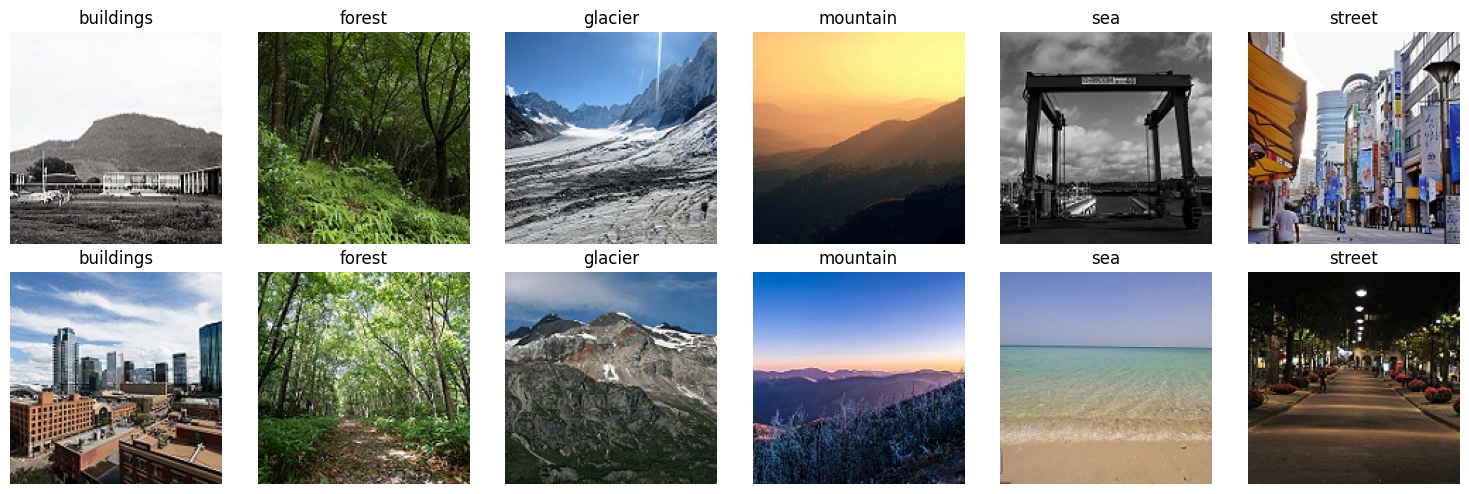

Shape (H, W, C): (150, 150, 3) dtype: uint8
Value range: 0 to 255
Top-left 3x3 of red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [6]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]

    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

arr = np.array(img)

print('Shape (H, W, C):', arr.shape, 'dtype:', arr.dtype)
print('Value range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of red channel:\n', arr[:3, :3, 0])

## Part 1: Dataset Exploration and Image Representation

The Intel Image Classification dataset contains six classes: buildings, forest, glacier, mountain, sea, and street.

The dataset contains 11,929 training images and 3,000 test images. Each image is represented as a numerical array containing pixel values for its color channels.

The sample image has a shape of (150, 150, 3), a data type of uint8, and pixel values ranging from 0 to 255. The three channels represent red, green, and blue.

**Visual Observation:** Mountain and glacier images may look similar because both can contain snow, ice, and rocky landscapes. I predict that these classes may be confused by the model. I will compare this prediction with the confusion matrix in Part 6.

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


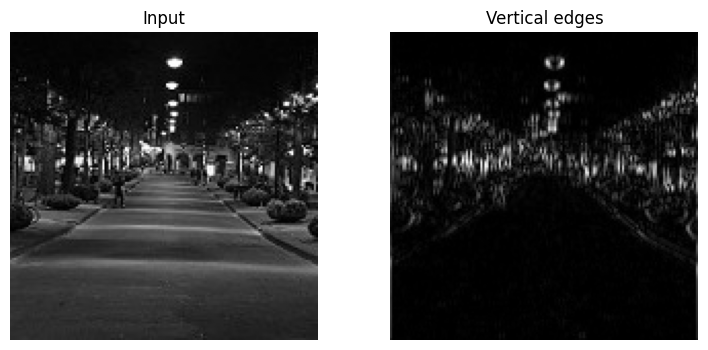

In [7]:
# A 5x5 image containing a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)

# Vertical-edge detection kernel
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)

out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())

# Apply the same kernel to a real image
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')

ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')

for a in ax:
    a.axis('off')

plt.show()

In [8]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(
    in_channels=3,
    out_channels=64,
    kernel_size=3,
    padding=1
)

dense = nn.Linear(150 * 150 * 3, 512)

print(f'Conv 3x3, 3 -> 64: {count(conv):,} parameters')
print(f'Dense 67,500 -> 512: {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)

for stride in [1, 2]:
    c = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=stride,
        padding=1
    )
    print(f'stride {stride}: output {tuple(c(t).shape)}')

print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64: 1,792 parameters
Dense 67,500 -> 512: 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


## Part 2: Convolution and Parameter Analysis

The convolution experiment produced three rows of [30, 30, 0]. The filter detects vertical intensity changes by comparing values on the left and right sides of the kernel.

### Parameter Calculations

**Convolution layer:**

Parameters = (3 × 3 × 3 + 1) × 64

= (27 + 1) × 64

= **1,792 parameters**

**Fully connected layer:**

Parameters = (67,500 × 512) + 512

= 34,560,000 + 512

= **34,560,512 parameters**

The dense layer has 19,286 times as many parameters as the convolution layer.

### Why Weight Sharing Matters

A convolutional filter uses the same weights at different image locations. This reduces the number of parameters and allows the model to detect similar features, such as edges, regardless of where they appear in an image.

The convolution output with stride 1 was (1, 64, 224, 224), while stride 2 produced (1, 64, 112, 112). A 2 × 2 max-pooling operation reduced the spatial dimensions from 224 × 224 to 112 × 112.

In [9]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Augmentation is used only for training images
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Validation and test images are not augmented
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Load the same training folder with two different transforms
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)

# Keep the split reproducible
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))

train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])

test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

# Create loaders
train_dl = DataLoader(
    train_ds, batch_size=64, shuffle=True, num_workers=2
)

val_dl = DataLoader(
    val_ds, batch_size=128, shuffle=False, num_workers=2
)

test_dl = DataLoader(
    test_ds, batch_size=128, shuffle=False, num_workers=2
)

print(len(train_ds), 'train |', len(val_ds), 'validation |',
      len(test_ds), 'test')

11929 train | 2105 validation | 3000 test


## Part 3: Image Transforms and Data Loaders

The dataset was divided into three subsets:

- Training: 11,929 images
- Validation: 2,105 images
- Testing: 3,000 images

Training images use random resized cropping, horizontal flipping, and color jitter for data augmentation. Validation and test images use resizing and ImageNet normalization without random augmentation.

The validation set helps compare models and select the best epoch, while the test set is reserved for final evaluation.

**Augmentation considerations:**

A vertical flip may create unrealistic orientations for buildings and street scenes. For handwritten digits, horizontal flipping can change a digit's meaning or make it invalid.

Separating validation and test data helps evaluate generalization without using the test set to select the model.

In [12]:
def run_epoch(model, loader, optimizer=None):
    """Train for one epoch if optimizer is supplied; otherwise evaluate."""
    training = optimizer is not None
    model.train(training)

    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)

            # Forward pass
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)

            if training:
                # Backpropagation and parameter update
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)

    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    """Train the model and retain its best validation checkpoint."""
    best_acc, best_state = -1.0, None

    for ep in range(epochs):
        t0 = time.time()

        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)

        history.append((tr_loss, va_loss, tr_acc, va_acc))

        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f'Epoch {ep + 1}: '
            f'train loss {tr_loss:.3f}, acc {tr_acc:.3f} | '
            f'val loss {va_loss:.3f}, acc {va_acc:.3f} | '
            f'{time.time() - t0:.0f}s'
        )

    model.load_state_dict(best_state)
    return best_acc

In [13]:
# Load a ResNet-18 pretrained on ImageNet
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze the pretrained network
for p in model.parameters():
    p.requires_grad = False

# Replace the final layer for our six classes
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f'Trainable {trainable:,} of {count(model):,} parameters')

# Train only the new classification head
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

best_feature = fit(model, opt, epochs=3, history=history)

print(f'Best validation accuracy, feature extraction: {best_feature:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s] 


Trainable 3,078 of 11,179,590 parameters
Epoch 1: train loss 0.588, acc 0.809 | val loss 0.327, acc 0.894 | 71s
Epoch 2: train loss 0.326, acc 0.890 | val loss 0.290, acc 0.899 | 36s
Epoch 3: train loss 0.299, acc 0.895 | val loss 0.276, acc 0.901 | 37s
Best validation accuracy, feature extraction: 0.901


## Part 4: Transfer Learning with Feature Extraction

A pretrained ResNet18 model was loaded with ImageNet weights. The pretrained layers were frozen, and a new fully connected layer was trained to classify the six scene categories.

Only 3,078 parameters were trainable out of approximately 11.18 million total parameters.

### Training Results

| Epoch | Training Loss | Training Accuracy | Validation Loss | Validation Accuracy |
|---|---:|---:|---:|---:|
| 1 | 0.588 | 80.9% | 0.327 | 89.4% |
| 2 | 0.326 | 89.0% | 0.290 | 89.9% |
| 3 | 0.299 | 89.5% | 0.276 | 90.1% |

The best validation accuracy was **90.1%**.

### Why Did Feature Extraction Work?

ResNet18 had already learned useful visual features from ImageNet, including edges, textures, shapes, and object patterns. These pretrained features can be reused for scene classification, so training only the new classification head can achieve good performance with relatively few trainable parameters.

In [16]:
# Unfreeze the last ResNet block
for p in model.layer4.parameters():
    p.requires_grad = True

# Use separate learning rates
opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},
    {'params': model.fc.parameters(), 'lr': 1e-3}
])

trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f'Trainable now: {trainable:,}')

best_finetuned = fit(model, opt, epochs=3, history=history)

print(f'Best validation accuracy, fine-tuned: {best_finetuned:.3f}')

Trainable now: 8,396,806
Epoch 1: train loss 0.094, acc 0.966 | val loss 0.229, acc 0.931 | 37s
Epoch 2: train loss 0.073, acc 0.973 | val loss 0.247, acc 0.938 | 37s
Epoch 3: train loss 0.072, acc 0.974 | val loss 0.244, acc 0.938 | 35s
Best validation accuracy, fine-tuned: 0.938


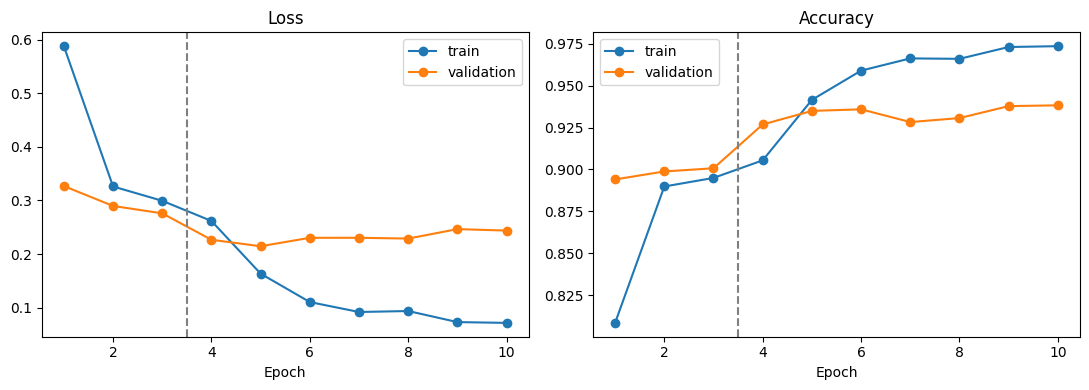

In [17]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Loss curves
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')

# Accuracy curves
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')

for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', linestyle='--')
    a.set_title(title)
    a.set_xlabel('Epoch')
    a.legend()

plt.tight_layout()
plt.show()

## Part 5: Fine-Tuning and Learning Curve Analysis

During fine-tuning, the final ResNet18 block (`layer4`) was unfrozen along with the classification head. A smaller learning rate of 0.0001 was used for the pretrained block, while the new classification head used a learning rate of 0.001.

### Fine-Tuning Results

| Epoch | Training Loss | Training Accuracy | Validation Loss | Validation Accuracy |
|---|---:|---:|---:|---:|
| 1 | 0.094 | 96.6% | 0.229 | 93.1% |
| 2 | 0.073 | 97.3% | 0.247 | 93.8% |
| 3 | 0.072 | 97.4% | 0.244 | 93.8% |

The best validation accuracy improved from 90.1% to 93.8%, an increase of **3.7 percentage points**.

### Learning Curve Interpretation

Training loss decreased during fine-tuning, while validation loss increased slightly after the first epoch. This suggests some potential overfitting, although validation accuracy remained high at 93.8%.

Training accuracy can be lower than validation accuracy because training images undergo random augmentation, making them more varied and challenging. Validation images do not receive random augmentation.

Fine-tuning allowed the final feature block to adapt to the target dataset and improved validation performance.

Test accuracy: 0.935
              precision    recall  f1-score   support

   buildings      0.928     0.938     0.933       437
      forest      0.994     0.994     0.994       474
     glacier      0.894     0.888     0.891       553
    mountain      0.908     0.886     0.897       525
         sea      0.945     0.984     0.964       510
      street      0.947     0.930     0.939       501

    accuracy                          0.935      3000
   macro avg      0.936     0.937     0.936      3000
weighted avg      0.935     0.935     0.935      3000



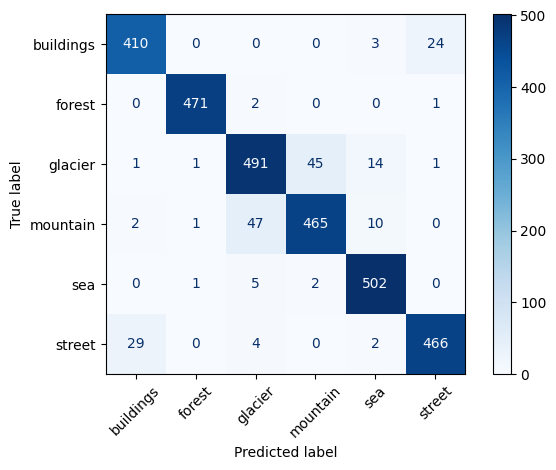

In [18]:
model.eval()

probs, preds, labels = [], [], []

with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()

        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)

probs = torch.cat(probs)
preds = torch.cat(preds)
labels = torch.cat(labels)

test_accuracy = (preds == labels).float().mean().item()
print(f'Test accuracy: {test_accuracy:.3f}')

print(classification_report(
    labels,
    preds,
    target_names=classes,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(labels, preds)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(cmap='Blues', xticks_rotation=45)

plt.tight_layout()
plt.show()

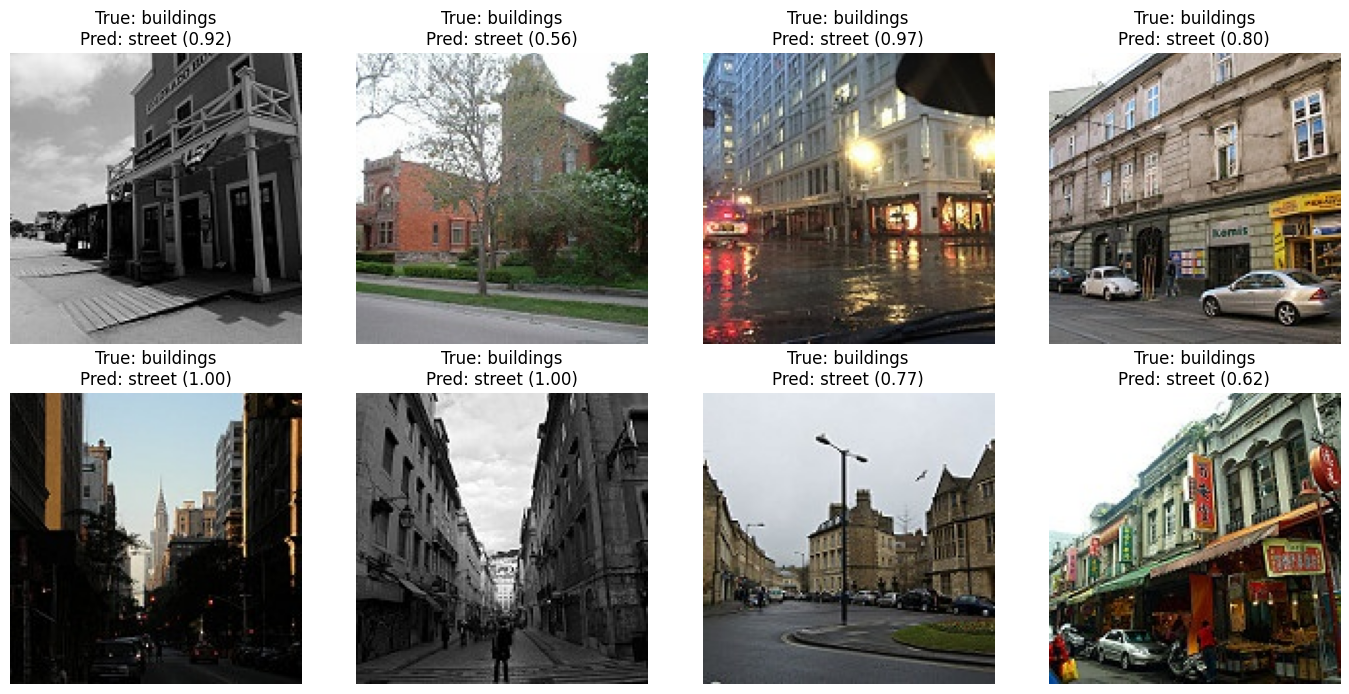

Number of errors displayed: 8


In [19]:
wrong = torch.where(preds != labels)[0][:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax in axes.flat:
    ax.axis('off')

for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]

    ax.imshow(Image.open(path))
    ax.set_title(
        f'True: {classes[labels[i]]}\n'
        f'Pred: {classes[preds[i]]} '
        f'({probs[i].max():.2f})'
    )

plt.tight_layout()
plt.show()

print('Number of errors displayed:', len(wrong))

In [21]:
x0, y0 = test_ds[0]

with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()

p = F.softmax(logits, dim=0)

print('True class:', classes[y0])

for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

print('Sum of probabilities:', p.sum().item())

True class: buildings
buildings  logit  11.04   probability 1.000
forest     logit  -9.36   probability 0.000
glacier    logit  -6.66   probability 0.000
mountain   logit  -7.50   probability 0.000
sea        logit  -8.43   probability 0.000
street     logit  -5.48   probability 0.000
Sum of probabilities: 0.9999999403953552


## Part 6: Final Evaluation and Error Analysis

The fine-tuned ResNet18 model achieved a test accuracy of **93.5%** on 3,000 test images.

### Class-Wise Results

| Class | Precision | Recall | F1-Score |
|---|---:|---:|---:|
| Buildings | 92.8% | 93.8% | 93.3% |
| Forest | 99.4% | 99.4% | 99.4% |
| Glacier | 89.4% | 88.8% | 89.1% |
| Mountain | 90.8% | 88.6% | 89.7% |
| Sea | 94.5% | 98.4% | 96.4% |
| Street | 94.7% | 93.0% | 93.9% |

Mountain had the lowest recall at 88.6%, followed by glacier at 88.8%. Forest was the best-performing class, with 99.4% recall.

### Confusion Matrix and Misclassified Images

The confusion matrix should be used to identify which pair of classes was confused most frequently. The error gallery provides examples for investigating these mistakes.

For at least two misclassified images, examine whether the scene is visually ambiguous, whether the predicted class is understandable from the image, or whether the dataset label may be incorrect.

**Comparison with the Part 1 prediction:** Check whether the pair predicted in Part 1 was among the most frequently confused pairs in the confusion matrix. Update this sentence after inspecting the actual counts.

### Softmax Prediction

Softmax converts the model's logits into probabilities that sum to approximately 1. For the first test image, the true class was buildings and the predicted class was also buildings, with a displayed probability of 1.000.

This is a correct prediction with high model confidence. However, confidence alone does not guarantee that a prediction is correct.

In [22]:
path = '/kaggle/working/resnet18_intel.pt'

torch.save(model.state_dict(), path)

print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


## Part 7: Project Summary and Next Steps

### Project Summary

This project used a pretrained ResNet18 model to classify images into six scene categories from the Intel Image Classification dataset.

- **Dataset:** Intel Image Classification
- **Classes:** 6
- **Model:** ResNet18 pretrained on ImageNet
- **Feature extraction validation accuracy:** 90.1%
- **Fine-tuning validation accuracy:** 93.8%
- **Final test accuracy:** 93.5%
- **Model file:** `resnet18_intel.pt`

Fine-tuning improved the best validation accuracy by 3.7 percentage points. The model performed particularly well on forest and sea images, while mountain and glacier remained comparatively challenging.

### Model Saving

The trained model was saved to `/kaggle/working/resnet18_intel.pt` for future use.

### Week 6 Proposal

For Week 6, I propose applying transfer learning to an image dataset from my own area of interest. One possible direction is electronics component classification, using a publicly available dataset of electronic components. This would explore how computer vision can help identify components from images.

### Conclusion

This lab provided practical experience with convolution operations, CNN parameter counts, image augmentation, transfer learning, fine-tuning, and model evaluation. The final model achieved 93.5% test accuracy, demonstrating the usefulness of pretrained models for image classification.